In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

In [ ]:
!wget -q https://os.unil.cloud.switch.ch/fma/fma_metadata.zip
!unzip -q fma_metadata.zip

In [ ]:
!wget -q https://os.unil.cloud.switch.ch/fma/fma_small.zip
!unzip -q fma_small.zip

In [ ]:
import os

print("FMA small exists:", os.path.exists("fma_small"))
print("Number of folders:", len(os.listdir("fma_small")))

print("\nExample folders:")
print(os.listdir("fma_small")[:10])


FMA small exists: True
Number of folders: 158

Example folders:
['022', '037', '020', '008', '119', '139', '095', '142', '125', '054']


In [ ]:
tracks = pd.read_csv(
    "fma_metadata/tracks.csv",
    header=[0, 1],
    index_col=0
)

print("Shape:", tracks.shape)
tracks.head()

Shape: (106574, 52)


album                                                     \
         comments         date_created        date_released engineer   
track_id                                                               
2               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
3               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
5               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
10              0  2008-11-26 01:45:08  2008-02-06 00:00:00      NaN   
20              0  2008-11-26 01:45:05  2009-01-06 00:00:00      NaN   

                                                                          \
         favorites id                                information listens   
track_id                                                                   
2                4  1                                    <p></p>    6073   
3                4  1                                    <p></p>    6073   
5                4  1                                    <p></p>    6073   
10               4  6                                        NaN   47632   
20               2  4  <p> "spiritual songs" from Nicky Cook</p>    2710   

                        ...       track                         \
         producer tags  ... information interest language_code   
track_id                ...                                      
2             NaN   []  ...         NaN     4656            en   
3             NaN   []  ...         NaN     1470            en   
5             NaN   []  ...         NaN     1933            en   
10            NaN   []  ...         NaN    54881            en   
20            NaN   []  ...         NaN      978            en   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
2         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1293      NaN   
3         Attribution-NonCommercial-ShareAlike 3.0 Inter...     514      NaN   
5         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1151      NaN   
10        Attribution-NonCommercial-NoDerivatives (aka M...   50135      NaN   
20        Attribution-NonCommercial-NoDerivatives (aka M...     361      NaN   

                                                 
         number publisher tags            title  
track_id                                         
2             3       NaN   []             Food  
3             4       NaN   []     Electric Ave  
5             6       NaN   []       This World  
10            1       NaN   []          Freeway  
20            3       NaN   []  Spiritual Level  

[5 rows x 52 columns]

In [ ]:
print(tracks["track"]["title"].head())
print()
print(tracks["track"]["genre_top"].head())
print()
print(tracks["track"]["listens"].head())

track_id
2                Food
3        Electric Ave
5          This World
10            Freeway
20    Spiritual Level
Name: title, dtype: object

track_id
2     Hip-Hop
3     Hip-Hop
5     Hip-Hop
10        Pop
20        NaN
Name: genre_top, dtype: object

track_id
2      1293
3       514
5      1151
10    50135
20      361
Name: listens, dtype: int64


In [ ]:
df = pd.DataFrame({
    "track_id": tracks.index,
    "title": tracks["track"]["title"],
    "listens": tracks["track"]["listens"],
    "genre": tracks["track"]["genre_top"]
})

df["listens"] = pd.to_numeric(df["listens"], errors="coerce")

df = df.dropna(subset=["listens", "title"])
df = df[df["listens"] > 0]

print("Total metadata tracks:", len(df))

Total metadata tracks: 106572


In [ ]:
def get_audio_path(track_id):
    track_id = int(track_id)
    folder = f"{track_id // 1000:03d}"
    filename = f"{track_id:06d}.mp3"

    return os.path.join(
        "fma_small",
        folder,
        filename
    )

df["audio_path"] = df["track_id"].apply(get_audio_path)

In [ ]:
df["exists"] = df["audio_path"].apply(os.path.exists)

df = df[df["exists"]].copy()
df = df.drop(columns=["exists"])

print("Tracks with available audio:", len(df))

Tracks with available audio: 8000


In [ ]:
df = df.sort_values(
    "listens",
    ascending=False
).reset_index(drop=True)

df[["track_id", "title", "listens"]].head()

,track_id,title,listens
0,42377,Night Owl,543252
1,24425,Fater Lee,433992
2,69170,Enthusiast,335215
3,54159,11 strANGE Ls,294602
4,55718,Kopeika,178139


In [ ]:
N = 500

hit_df = df.head(N).copy()
not_hit_df = df.tail(N).copy()

hit_df["label"] = 1
not_hit_df["label"] = 0

dataset = pd.concat(
    [hit_df, not_hit_df],
    ignore_index=True
)

dataset = dataset.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total:", len(dataset))
print(dataset["label"].value_counts())

Total: 1000
label
0    500
1    500
Name: count, dtype: int64


In [ ]:
print(dataset[["track_id", "title", "listens", "label"]].head(10))

   track_id                                 title  listens  label
0      1649                            Inis Meain      673      0
1     76069  Still the River Flows (Rhyming Song)      570      0
2     23039  First Comes Rug Burn Then Comes Fire      568      0
3     35184                                U Fine      604      0
4      6439                             Crossover    13720      1
5     35608                      Second Hand News      599      0
6     52001                  Massalia dub selecta      623      0
7    132786                              PNC Bach      677      0
8     92131                                   Out      504      0
9    126103                             Extra Pay    25235      1


In [ ]:
print("Total songs:", len(dataset))

print("\nLabel distribution:")
print(dataset["label"].value_counts())

print("\nSample:")
print(dataset[["track_id", "title", "listens", "label"]].head(10))

print("\nAudio files available:",
      dataset["audio_path"].apply(os.path.exists).sum())


Total songs: 1000

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Sample:
   track_id                                 title  listens  label
0      1649                            Inis Meain      673      0
1     76069  Still the River Flows (Rhyming Song)      570      0
2     23039  First Comes Rug Burn Then Comes Fire      568      0
3     35184                                U Fine      604      0
4      6439                             Crossover    13720      1
5     35608                      Second Hand News      599      0
6     52001                  Massalia dub selecta      623      0
7    132786                              PNC Bach      677      0
8     92131                                   Out      504      0
9    126103                             Extra Pay    25235      1

Audio files available: 1000


In [ ]:
def extract_repeated_section(audio_path, duration=15):
    y, sr = librosa.load(audio_path, sr=22050, mono=True)

    target_length = int(duration * sr)

    # If song is shorter than 15 seconds
    if len(y) <= target_length:
        return y, sr

    # Convert audio to mel spectrogram
    S = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_mels=64
    )

    S_db = librosa.power_to_db(S, ref=np.max)

    window_frames = int(duration * sr / 512)

    best_score = -1
    best_start = 0

    # Compare 15-second sections
    for start in range(0, S_db.shape[1] - window_frames, 10):

        segment = S_db[:, start:start + window_frames]

        for other_start in range(
            start + window_frames,
            S_db.shape[1] - window_frames,
            10
        ):
            other = S_db[:, other_start:other_start + window_frames]

            if segment.shape != other.shape:
                continue

            a = segment.flatten()
            b = other.flatten()

            similarity = np.dot(a, b) / (
                np.linalg.norm(a) * np.linalg.norm(b) + 1e-10
            )

            if similarity > best_score:
                best_score = similarity
                best_start = start

    start_sample = best_start * 512
    end_sample = start_sample + target_length

    return y[start_sample:end_sample], sr

In [ ]:
test_audio = dataset.iloc[0]["audio_path"]

y_test, sr_test = extract_repeated_section(test_audio)

print("Sample rate:", sr_test)
print("Audio samples:", len(y_test))
print("Duration:", len(y_test) / sr_test, "seconds")

Sample rate: 22050
Audio samples: 330750
Duration: 15.0 seconds


In [ ]:
def extract_features(y, sr):
    features = {}

    # MFCC: 13 coefficients
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    # Chroma
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    features["chroma_mean"] = np.mean(chroma)
    features["chroma_std"] = np.std(chroma)

    # RMS Energy
    rms = librosa.feature.rms(y=y)
    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)

    # Spectral Centroid
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features["centroid_mean"] = np.mean(centroid)
    features["centroid_std"] = np.std(centroid)

    # Spectral Bandwidth
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features["bandwidth_mean"] = np.mean(bandwidth)
    features["bandwidth_std"] = np.std(bandwidth)

    # Spectral Rolloff
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    features["rolloff_mean"] = np.mean(rolloff)
    features["rolloff_std"] = np.std(rolloff)

    # Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(y)
    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)

    return features

In [ ]:
features_test = extract_features(y_test, sr_test)

print("Number of features:", len(features_test))
print(features_test)

Number of features: 38
{'mfcc_1_mean': np.float32(21.04813), 'mfcc_1_std': np.float32(25.429478), 'mfcc_2_mean': np.float32(108.987885), 'mfcc_2_std': np.float32(12.923193), 'mfcc_3_mean': np.float32(-6.0492005), 'mfcc_3_std': np.float32(9.670588), 'mfcc_4_mean': np.float32(12.8463335), 'mfcc_4_std': np.float32(8.034524), 'mfcc_5_mean': np.float32(0.41906422), 'mfcc_5_std': np.float32(5.84279), 'mfcc_6_mean': np.float32(13.298692), 'mfcc_6_std': np.float32(4.6228104), 'mfcc_7_mean': np.float32(1.8819468), 'mfcc_7_std': np.float32(4.8509965), 'mfcc_8_mean': np.float32(5.506822), 'mfcc_8_std': np.float32(5.5922184), 'mfcc_9_mean': np.float32(-4.057516), 'mfcc_9_std': np.float32(4.44874), 'mfcc_10_mean': np.float32(7.4195657), 'mfcc_10_std': np.float32(5.5183825), 'mfcc_11_mean': np.float32(-2.7574813), 'mfcc_11_std': np.float32(5.3313017), 'mfcc_12_mean': np.float32(0.5060314), 'mfcc_12_std': np.float32(6.3084493), 'mfcc_13_mean': np.float32(-9.170431), 'mfcc_13_std': np.float32(6.104221

In [ ]:
all_features = []

for _, row in tqdm(dataset.iterrows(), total=len(dataset)):
    try:
        # Extract repeated 15-second section
        y, sr = extract_repeated_section(row["audio_path"])

        # Extract audio features
        features = extract_features(y, sr)

        # Add label and track ID
        features["track_id"] = row["track_id"]
        features["label"] = row["label"]

        all_features.append(features)

    except Exception as e:
        print(f"Error processing track {row['track_id']}: {e}")

feature_df = pd.DataFrame(all_features)

print("Dataset shape:", feature_df.shape)

 63%|██████▎   | 628/1000 [03:49<02:02,  3.03it/s]/usr/local/lib/python3.13/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
100%|██████████| 1000/1000 [06:17<00:00,  2.65it/s]

Dataset shape: (1000, 40)


In [ ]:
print("\nMissing values:")
print(feature_df.isnull().sum().sum())


Missing values:
0


In [ ]:
X = feature_df.drop(columns=["track_id", "label"])
y = feature_df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 38)
y shape: (1000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training samples: 800
Testing samples: 200

Training labels:
label
1    400
0    400
Name: count, dtype: int64

Testing labels:
label
1    100
0    100
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM trained successfully.")

SVM trained successfully.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

models_predictions = {
    "Logistic Regression": logistic_pred,
    "SVM": svm_pred,
    "Random Forest": rf_pred
}

for name, predictions in models_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.680   0.683673    0.67  0.676768
1                  SVM     0.665   0.666667    0.66  0.663317
2        Random Forest     0.645   0.652632    0.62  0.635897


In [ ]:
from sklearn.metrics import confusion_matrix

for name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    print(f"\n{name}")
    print(cm)


Logistic Regression
[[69 31]
 [33 67]]

SVM
[[67 33]
 [34 66]]

Random Forest
[[67 33]
 [38 62]]


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [ ]:
gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, gb_pred),
    "Precision": precision_score(y_test, gb_pred),
    "Recall": recall_score(y_test, gb_pred),
    "F1 Score": f1_score(y_test, gb_pred)
}

print(gb_results)

{'Model': 'Gradient Boosting', 'Accuracy': 0.67, 'Precision': 0.6770833333333334, 'Recall': 0.65, 'F1 Score': 0.6632653061224489}


In [ ]:
results.append(gb_results)

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.680   0.683673    0.67  0.676768
1                  SVM     0.665   0.666667    0.66  0.663317
2        Random Forest     0.645   0.652632    0.62  0.635897
3    Gradient Boosting     0.670   0.677083    0.65  0.663265


In [ ]:
gb_cm = confusion_matrix(y_test, gb_pred)

print("Gradient Boosting")
print(gb_cm)

Gradient Boosting
[[69 31]
 [35 65]]


In [ ]:
results_df.to_csv("model_results.csv", index=False)

print("Complete results saved.")
print(results_df)

Complete results saved.
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.680   0.683673    0.67  0.676768
1                  SVM     0.665   0.666667    0.66  0.663317
2        Random Forest     0.645   0.652632    0.62  0.635897
3    Gradient Boosting     0.670   0.677083    0.65  0.663265


<Figure size 900x500 with 0 Axes>

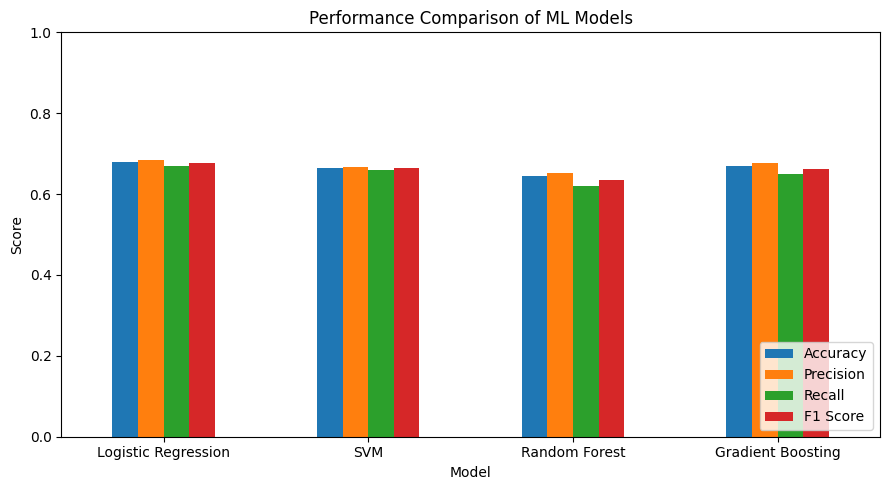

In [ ]:
plt.figure(figsize=(9, 5))

results_plot = results_df.set_index("Model")

results_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

EXTRA FEATURES


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    lr_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("\nBest CV F1:")
print(lr_grid.best_score_)

Best Logistic Regression parameters:
{'C': 0.01, 'solver': 'liblinear'}

Best CV F1:
0.6568945235361241


In [ ]:
best_lr = lr_grid.best_estimator_

tuned_lr_pred = best_lr.predict(X_test_scaled)

print("Tuned Logistic Regression")
print("-------------------------")
print("Accuracy :", accuracy_score(y_test, tuned_lr_pred))
print("Precision:", precision_score(y_test, tuned_lr_pred))
print("Recall   :", recall_score(y_test, tuned_lr_pred))
print("F1 Score :", f1_score(y_test, tuned_lr_pred))

Tuned Logistic Regression
-------------------------
Accuracy : 0.655
Precision: 0.6565656565656566
Recall   : 0.65
F1 Score : 0.6532663316582915


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest CV F1:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best CV F1:
0.7014041181705852


In [ ]:
best_rf = rf_grid.best_estimator_

tuned_rf_pred = best_rf.predict(X_test)

print("Tuned Random Forest")
print("-------------------")
print("Accuracy :", accuracy_score(y_test, tuned_rf_pred))
print("Precision:", precision_score(y_test, tuned_rf_pred))
print("Recall   :", recall_score(y_test, tuned_rf_pred))
print("F1 Score :", f1_score(y_test, tuned_rf_pred))

Tuned Random Forest
-------------------
Accuracy : 0.69
Precision: 0.6938775510204082
Recall   : 0.68
F1 Score : 0.6868686868686869


In [ ]:
tuned_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (Baseline)",
        "Accuracy": accuracy_score(y_test, logistic_pred),
        "Precision": precision_score(y_test, logistic_pred),
        "Recall": recall_score(y_test, logistic_pred),
        "F1 Score": f1_score(y_test, logistic_pred)
    },
    {
        "Model": "Logistic Regression (Tuned)",
        "Accuracy": accuracy_score(y_test, tuned_lr_pred),
        "Precision": precision_score(y_test, tuned_lr_pred),
        "Recall": recall_score(y_test, tuned_lr_pred),
        "F1 Score": f1_score(y_test, tuned_lr_pred)
    },
    {
        "Model": "Random Forest (Baseline)",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1 Score": f1_score(y_test, rf_pred)
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": accuracy_score(y_test, tuned_rf_pred),
        "Precision": precision_score(y_test, tuned_rf_pred),
        "Recall": recall_score(y_test, tuned_rf_pred),
        "F1 Score": f1_score(y_test, tuned_rf_pred)
    }
])

print(tuned_comparison)

                            Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression (Baseline)     0.680   0.683673    0.67  0.676768
1     Logistic Regression (Tuned)     0.655   0.656566    0.65  0.653266
2        Random Forest (Baseline)     0.645   0.652632    0.62  0.635897
3           Random Forest (Tuned)     0.690   0.693878    0.68  0.686869
